# 3. Preprocesamiento (misma lógica en ambos entornos)

| Paso | scikit-learn (`ctr.features`) | PySpark (`ctr.spark_ctr`) |
|---|---|---|
| Raras → `__RARE__` | conteo en entrenamiento, umbral `rare_min_count` | igual (groupBy + join broadcast) |
| Alta cardinalidad | hashing de `"columna=valor"` (MurmurHash3, sin signo alterno) | `FeatureHasher` |
| Baja cardinalidad | one-hot por código | `StringIndexer` + `OneHotEncoder` |
| Frecuencia | `log1p(conteo)` + `StandardScaler` | igual + `StandardScaler` de MLlib |
| Target encoding | `TargetEncoder` out-of-fold (5 particiones) | **no implementado** (ver limitación) |
| Cruces | `site_id×device_type`, `app_id×device_type`, `banner_pos×device_conn_type` | solo en scikit-learn (ablación) |

Todos los parámetros (vocabularios, conteos, escaladores, codificador objetivo) se ajustan
**solo con entrenamiento**; las categorías nuevas en validación/prueba caen en `__RARE__`.

**Diferencia documentada.** Los dos hashers usan MurmurHash3 sobre `"columna=valor"`, pero con
semillas e implementaciones distintas: los índices no coinciden entre entornos, aunque la lógica
y la tasa esperada de colisiones son las mismas.

**Limitación del target encoding.** Hacerlo out-of-fold en Spark exige implementar el
cross-fitting a mano (no existe en MLlib). Se deja solo en scikit-learn, como pide el enunciado.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ctr.nbutils import setup, savefig, show, SERIES, ENC_COLOR
from ctr import data
from ctr.features import CTRFeaturizer
from ctr.bench import measure

cfg, RES, FIG = setup()
N = cfg["ablation_size"]
tr = data.read_sample(cfg, "train", N)
va, te = data.eval_sets(cfg)
ytr = tr["click"].to_numpy()
print(f"Muestra de entrenamiento: {tr.height:,} filas | validación: {va.height:,} | prueba: {te.height:,}")

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results


Muestra de entrenamiento: 300,000 filas | validación: 1,000,000 | prueba: 4,218,938


## 3.1 Agrupación de raras y categorías no vistas

In [2]:
feat = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"]).fit(tr)
c_tr, c_va, c_te = feat.encode(tr), feat.encode(va), feat.encode(te)
rows = []
for j, c in enumerate(feat.cols):
    rows.append({"variable": c, "categorias_train": tr[c].n_unique(), "vocabulario_tras_raras": len(feat.names[c]),
                 "pct_train_RARE": (c_tr[:, j] == 0).mean() * 100,
                 "pct_valid_RARE_o_nueva": (c_va[:, j] == 0).mean() * 100,
                 "pct_test_RARE_o_nueva": (c_te[:, j] == 0).mean() * 100})
rare = pd.DataFrame(rows).sort_values("categorias_train", ascending=False)
rare.to_csv(RES / "prep_raras.csv", index=False)
show(rare, 30, "{:.2f}")

,variable,categorias_train,vocabulario_tras_raras,pct_train_RARE,pct_valid_RARE_o_nueva,pct_test_RARE_o_nueva
5,device_ip,199859,423,88.73,89.33,93.14
4,device_id,48514,11,17.23,20.55,15.09
6,device_model,4071,1127,4.89,5.74,6.62
2,app_id,2049,320,2.11,2.35,2.85
0,site_id,2001,460,2.36,2.41,2.04
1,site_domain,1972,362,2.05,2.21,1.71
7,C14,1696,794,1.88,26.54,39.10
8,C17,352,294,0.17,23.73,33.80
10,C20,158,132,0.08,0.10,0.15
3,app_domain,139,34,0.12,0.09,0.17


## 3.2 Hashing: colisiones, memoria y tiempo según la dimensión

Colisión = dos categorías distintas del vocabulario (dentro de las columnas de alta
cardinalidad) que caen en el mismo índice. Se reporta el porcentaje de tokens que comparten
índice con al menos otro.

Tokens de alta cardinalidad en el vocabulario: 4,064


,codificacion,dim_entrada,pct_tokens_colisionados,transform_s,transform_rows_per_s,MB_matriz,transform_peak_mb
0,hash 2^12,4208,62.697,0.265,1133363.165,56.065,3323.145
1,hash 2^14,16496,21.949,0.206,1454846.849,56.074,3380.402
2,hash 2^16,65648,6.914,0.186,1614216.243,56.076,3380.590
3,freq,24,NaN,0.342,877379.300,27.466,3353.520
4,target,24,NaN,1.762,170230.117,27.466,3416.520


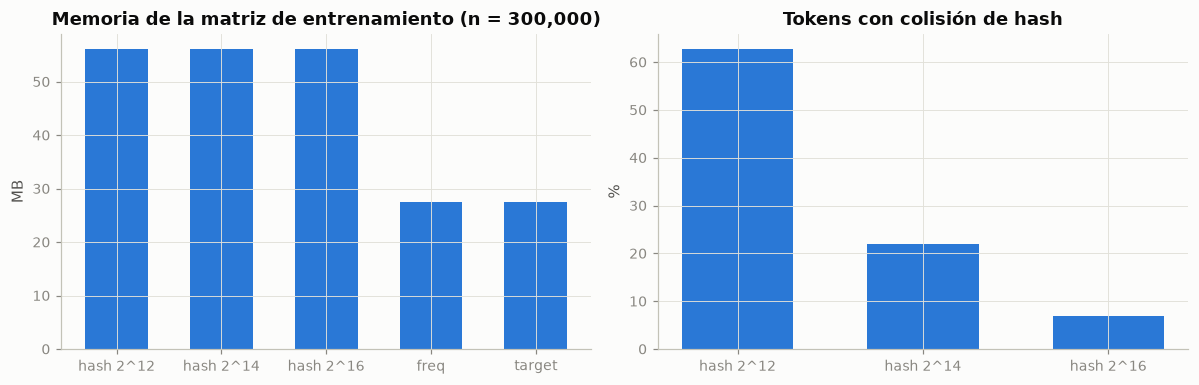

In [3]:
tokens = [(c, v) for c in feat.high_card for v in feat.names[c]]
print(f"Tokens de alta cardinalidad en el vocabulario: {len(tokens):,}")
enc_rows = []
for dim in cfg["hash_dims"]:
    luts, offsets, dtot = feat._hash_lut(dim)
    allidx = np.concatenate([luts[c] for c in feat.high_card])
    _, inv, cnt = np.unique(allidx, return_inverse=True, return_counts=True)
    rec = {"codificacion": f"hash 2^{int(np.log2(dim))}", "dim_entrada": dtot,
           "pct_tokens_colisionados": (cnt[inv] > 1).mean() * 100}
    with measure(rec, "transform", tr.height):
        X = feat.transform_codes(c_tr, "hash", dim)
    rec["MB_matriz"] = (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 2**20
    enc_rows.append(rec)
for enc in ["freq", "target"]:
    rec = {"codificacion": enc, "dim_entrada": len(feat.cols), "pct_tokens_colisionados": np.nan}
    with measure(rec, "transform", tr.height):
        X = feat.transform_codes(c_tr, enc, y=ytr, fit=True)
    rec["MB_matriz"] = X.nbytes / 2**20
    enc_rows.append(rec)
enc_tab = pd.DataFrame(enc_rows)[["codificacion", "dim_entrada", "pct_tokens_colisionados", "transform_s",
                                  "transform_rows_per_s", "MB_matriz", "transform_peak_mb"]]
enc_tab.to_csv(RES / "prep_codificaciones.csv", index=False)
show(enc_tab, 10, "{:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].bar(enc_tab["codificacion"], enc_tab["MB_matriz"], color=SERIES[0], width=0.6)
axs[0].set_title(f"Memoria de la matriz de entrenamiento (n = {tr.height:,})"); axs[0].set_ylabel("MB")
h = enc_tab.dropna(subset=["pct_tokens_colisionados"])
axs[1].bar(h["codificacion"], h["pct_tokens_colisionados"], color=SERIES[0], width=0.6)
axs[1].set_title("Tokens con colisión de hash"); axs[1].set_ylabel("%")
savefig(fig, FIG, "03_memoria_colisiones")

## 3.3 Target encoding out-of-fold: verificación anti-fuga

Si se codificara el entrenamiento con un codificador ajustado sobre las mismas filas, cada fila
vería su propia etiqueta. Comparamos la AUC de una regresión logística sobre la codificación
**in-sample** vs **out-of-fold**, evaluada en entrenamiento y en validación. Una brecha grande
entre entrenamiento y validación con la versión in-sample evidencia la fuga.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import TargetEncoder
yva = va["click"].to_numpy()
te_in = TargetEncoder(target_type="binary").fit(c_tr, ytr)
X_in, X_oof = te_in.transform(c_tr), TargetEncoder(target_type="binary").fit_transform(c_tr, ytr)
rows = []
for name, Xtr_ in [("in-sample (con fuga)", X_in), ("out-of-fold", X_oof)]:
    lr = LogisticRegression(max_iter=300).fit(Xtr_, ytr)
    rows.append({"variante": name, "AUC_train": roc_auc_score(ytr, lr.predict_proba(Xtr_)[:, 1]),
                 "AUC_valid": roc_auc_score(yva, lr.predict_proba(te_in.transform(c_va))[:, 1])})
show(pd.DataFrame(rows))

,variante,AUC_train,AUC_valid
0,in-sample (con fuga),0.7358,0.7222
1,out-of-fold,0.7258,0.7243


## 3.4 Cruces de variables (ablación)

In [5]:
feat_x = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"], crosses=cfg["features"]["crosses"]).fit(tr)
show(pd.DataFrame({"cruce": [c for c in feat_x.cols if "_x_" in c],
                   "vocabulario": [len(feat_x.names[c]) for c in feat_x.cols if "_x_" in c]}))

,cruce,vocabulario
0,site_id_x_device_type,463
1,app_id_x_device_type,323
2,banner_pos_x_device_conn_type,13


## 3.5 Verificación de equivalencia con PySpark

Se ajusta el preprocesamiento de Spark sobre **la misma muestra** y se comparan, columna por
columna, el tamaño del vocabulario y el conteo del grupo `__RARE__`. Deben coincidir exactamente.

In [6]:
from ctr import spark_ctr as S
spark = S.get_spark(cfg)
sdf = spark.read.parquet(str(data.sample_path(cfg, "train", N)))
sfeat = S.SparkFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"]).fit(sdf)
chk = pd.DataFrame({"variable": feat.cols,
                    "vocab_sklearn": [len(feat.names[c]) - 1 for c in feat.cols],
                    "vocab_spark": [sfeat.vocab[c].count() for c in feat.cols],
                    "rare_sklearn": [int(feat.counts[c][0]) for c in feat.cols],
                    "rare_spark": [int(sfeat.rare_cnt[c]) for c in feat.cols]})
chk["coincide"] = (chk.vocab_sklearn == chk.vocab_spark) & (chk.rare_sklearn == chk.rare_spark)
show(chk, 30)
assert chk["coincide"].all(), "El preprocesamiento de Spark y scikit-learn no coincide"
print("Equivalencia verificada: mismos vocabularios y mismos conteos de __RARE__ en ambos entornos.")
spark.stop()

,variable,vocab_sklearn,vocab_spark,rare_sklearn,rare_spark,coincide
0,site_id,459,459,7090,7090,True
1,site_domain,361,361,6149,6149,True
2,app_id,319,319,6331,6331,True
3,app_domain,33,33,373,373,True
4,device_id,10,10,51680,51680,True
5,device_ip,422,422,266182,266182,True
6,device_model,1126,1126,14657,14657,True
7,C14,793,793,5648,5648,True
8,C17,293,293,519,519,True
9,C19,55,55,33,33,True


Equivalencia verificada: mismos vocabularios y mismos conteos de __RARE__ en ambos entornos.
